# 3. Logistic regression from scratch

The model (`src/logreg.py`, NumPy only):

```
z = X·w + b                                   score for every crash
p = σ(z) = 1 / (1 + e^(−z))                   score → probability of a fatal crash
L = −(1/n) Σ [ y·ln p + (1−y)·ln(1−p) ]       binary cross-entropy: big when confidently wrong
∂L/∂w = (1/n)·Xᵀ(p − y),   ∂L/∂b = mean(p − y)  gradient
w ← w − lr·∂L/∂w                              gradient descent
```

In [1]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.append("..")
import numpy as np
import matplotlib.pyplot as plt
from src.logreg import sigmoid, loss, gradients, train, predict_proba, numerical_gradient

## 1. Unit tests on numbers computed by hand

In [2]:
print(sigmoid(np.array([-2, 0, 2])))            # expect [0.119 0.5 0.881]
print(loss(np.array([0.5]), np.array([1])))     # expect 0.693
X = np.array([[1, 0], [1, 1], [0, 1]])
y = np.array([0, 1, 0])
p = np.array([0.2, 0.5, 0.1])
print(gradients(X, y, p))                       # expect ([-0.1, -0.133], -0.067)

[0.11920292 0.5        0.88079708]
0.6931471805599453
(array([-0.1       , -0.13333333]), np.float64(-0.06666666666666667))


## 2. Load features; drop columns that never change
`participant_categories_Все участники` is 1 in every crash, so it carries no information and only duplicates the bias.

In [3]:
data = np.load("../data/features.npz", allow_pickle=True)
X_train, y_train = data["X_train"], data["y_train"]
X_val, y_val = data["X_val"], data["y_val"]
columns = data["columns"]
print(X_train.shape, y_train.mean())

(77181, 261) 0.04652699498581257


In [4]:
keep = X_train.std(axis=0) > 0
X_train, X_val = X_train[:, keep], X_val[:, keep]
columns = columns[keep]
print(X_train.shape, "removed:", (~keep).sum())

(77181, 260) removed: 1


## 3. Gradient check
Calculus says the gradient is `(1/n)·Xᵀ(p − y)`. To check it independently, nudge each weight by a tiny ε up and down
and measure how the loss actually changes: `(L(w+ε) − L(w−ε)) / 2ε`. If the formula and the nudging agree to many
decimal places, the backward pass is correct.

In [5]:
rng = np.random.default_rng(0)
sample = rng.choice(len(y_train), size=2000, replace=False)   # small sample: the check is slow
Xs, ys = X_train[sample], y_train[sample]
w_rand = rng.normal(0, 0.1, size=Xs.shape[1])                  # random weights, not zeros, so the test is not trivial
b_rand = -1.0

dw, db = gradients(Xs, ys, predict_proba(Xs, w_rand, b_rand))  # formula
num_dw, num_db = numerical_gradient(Xs, ys, w_rand, b_rand)    # nudging each weight

print("largest difference in dw:", np.max(np.abs(dw - num_dw)))
print("difference in db:        ", abs(db - num_db))
print("relative error:          ", np.linalg.norm(dw - num_dw) / np.linalg.norm(dw + num_dw))

largest difference in dw: 6.754817327226173e-11
difference in db:         7.295025694631363e-12
relative error:           4.980174624483219e-10


## 4. Baseline: the number to beat
Give every crash the same probability (the train fatal rate). A useful model must have lower validation loss than this.

In [6]:
rate = y_train.mean()
print("baseline val loss:", loss(np.full(len(y_val), rate), y_val))

baseline val loss: 0.15707470837550863


## 5. Train
Full-batch gradient descent: every epoch uses all 77,181 training crashes. With all weights at 0, every p = 0.5,
so the first loss must be ln 2 ≈ 0.693.

In [7]:
w, b, hist = train(X_train, y_train, lr=0.5, epochs=1000, X_val=X_val, y_val=y_val)
print("final train:", hist["train"][-1], " final val:", hist["val"][-1])

epoch 0: train loss 0.6931
epoch 100: train loss 0.1781
epoch 200: train loss 0.1745
epoch 300: train loss 0.1730
epoch 400: train loss 0.1720
epoch 500: train loss 0.1713
epoch 600: train loss 0.1707
epoch 700: train loss 0.1702
epoch 800: train loss 0.1698
epoch 900: train loss 0.1695
final train: 0.169205474374049  final val: 0.14156051765997982


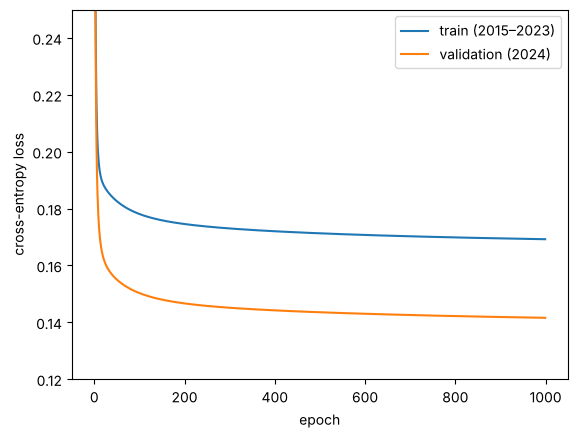

In [8]:
plt.plot(hist["train"], label="train (2015–2023)")
plt.plot(hist["val"], label="validation (2024)")
plt.xlabel("epoch")
plt.ylabel("cross-entropy loss")
plt.legend()
plt.ylim(0.12, 0.25)
plt.savefig("../plots/loss_logreg.png", dpi=150)
plt.show()

## 6. Is it useful? (validation, 2024)
**ROC-AUC:** pick a random fatal and a random non-fatal crash; AUC is the probability the model gives the fatal one
a higher risk. 0.5 = coin flip. scikit-learn is used only to compute this metric.

In [9]:
from sklearn.metrics import roc_auc_score
p_val = predict_proba(X_val, w, b)
print("val ROC-AUC:", roc_auc_score(y_val, p_val))

val ROC-AUC: 0.7389157798487831


**Top 10%:** if someone could only look at the 10% of crashes the model rates riskiest, how many deadly crashes would they find?

In [10]:
order = np.argsort(-p_val)
top = order[: len(p_val) // 10]
print("fatal rate in top 10%:", y_val[top].mean())
print("share of all deaths in top 10%:", y_val[top].sum() / y_val.sum())

fatal rate in top 10%: 0.12655367231638417
share of all deaths in top 10%: 0.34890965732087226


## 7. What is linked to deadly crashes?
`e^weight` is an **odds ratio**: x1.8 means 1.8 times the odds of a death.
- For yes/no flags (pedestrians involved, motorcyclists involved…) it compares "present" with "absent".
- For one-hot groups (crash type, lighting, hour) only comparisons **inside the same group** are meaningful.
- This is correlation, not causation.

In [11]:
idx = np.argsort(w)
print("RAISE risk:")
for i in idx[-10:][::-1]:
    print(f"  {columns[i]:70s} odds x{np.exp(w[i]):.2f}")
print("LOWER risk:")
for i in idx[:10]:
    print(f"  {columns[i]:70s} odds x{np.exp(w[i]):.2f}")

RAISE risk:
  participant_categories_Пешеходы                                        odds x1.80
  participant_categories_Мотоциклисты                                    odds x1.72
  category_Наезд на препятствие                                          odds x1.48
  light_В темное время суток, освещение отсутствует                      odds x1.35
  hour_0                                                                 odds x1.30
  participants_count                                                     odds x1.27
  hour_5                                                                 odds x1.26
  hour_2                                                                 odds x1.24
  hour_6                                                                 odds x1.22
  region_Щаповское поселение                                             odds x1.21
LOWER risk:
  category_Столкновение                                                  odds x0.40
  light_Светлое время суток                         

## 8. Final test on 2025 — run once, model frozen
Nothing above was changed after this cell was run.

In [12]:
X_test, y_test = data["X_test"][:, keep], data["y_test"]
p_test = predict_proba(X_test, w, b)

print("test loss:", loss(p_test, y_test))
print("baseline test loss:", loss(np.full(len(y_test), rate), y_test))
print("test ROC-AUC:", roc_auc_score(y_test, p_test))

top = np.argsort(-p_test)[: len(p_test) // 10]
print("fatal rate overall:", y_test.mean())
print("fatal rate in top 10%:", y_test[top].mean())
print("share of all deaths in top 10%:", y_test[top].sum() / y_test.sum())

test loss: 0.1335511166710771
baseline test loss: 0.15070000309999543
test ROC-AUC: 0.7537209206231148
fatal rate overall: 0.03412356321839081
fatal rate in top 10%: 0.13293413173652693
share of all deaths in top 10%: 0.3894736842105263


## 9. Calibration: are the probabilities right, not just the ranking?
Sort crashes by predicted risk, cut them into 10 equal groups, and compare the average predicted risk with the real fatal rate.
Points near the dashed line mean the probabilities can be taken at face value.

Fatal crashes became rarer over time (4.65% in train, 3.41% in 2025), so I expected the model to predict too high.
This is a check on the frozen model, not tuning.

group | predicted 2024 | real 2024 | predicted 2025 | real 2025
    1 |          0.8% |      1.0% |           0.8% |      0.5%
    2 |          1.3% |      0.7% |           1.2% |      0.7%
    3 |          1.7% |      0.6% |           1.6% |      2.0%
    4 |          2.1% |      2.5% |           1.9% |      1.2%
    5 |          2.6% |      2.9% |           2.3% |      1.7%
    6 |          3.1% |      2.3% |           2.7% |      2.9%
    7 |          3.8% |      3.8% |           3.3% |      2.0%
    8 |          4.8% |      3.3% |           4.3% |      3.8%
    9 |          6.5% |      6.5% |           5.9% |      6.0%
   10 |         11.8% |     12.7% |          10.7% |     13.3%

average predicted vs real, 2024: 3.86% vs 3.62%
average predicted vs real, 2025: 3.47% vs 3.41%


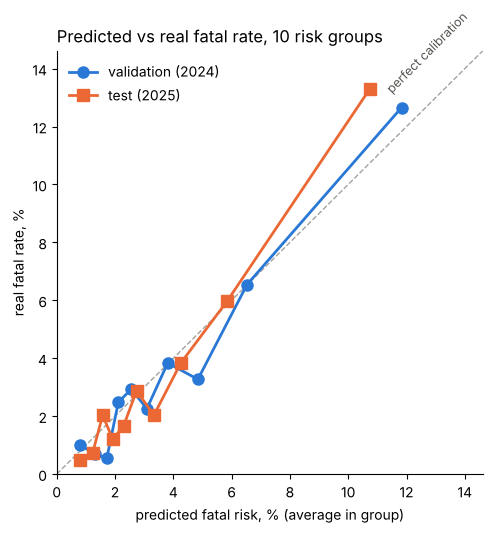

In [13]:
def calibration_table(p, y, groups=10):
    """Sort crashes by predicted risk, cut into equal groups,
    compare average predicted risk with the real fatal rate in each group."""
    order = np.argsort(p)
    parts = np.array_split(order, groups)
    return np.array([p[g].mean() for g in parts]), np.array([y[g].mean() for g in parts])

pred_val, real_val = calibration_table(p_val, y_val)
pred_test, real_test = calibration_table(p_test, y_test)

print("group | predicted 2024 | real 2024 | predicted 2025 | real 2025")
for i in range(10):
    print(f"{i+1:>5} | {pred_val[i]:>13.1%} | {real_val[i]:>9.1%} | {pred_test[i]:>14.1%} | {real_test[i]:>9.1%}")
print()
print(f"average predicted vs real, 2024: {p_val.mean():.2%} vs {y_val.mean():.2%}")
print(f"average predicted vs real, 2025: {p_test.mean():.2%} vs {y_test.mean():.2%}")

fig, ax = plt.subplots(figsize=(5.5, 5.5))
top = max(pred_val.max(), real_val.max(), pred_test.max(), real_test.max()) * 100 * 1.1
ax.plot([0, top], [0, top], color="#a3a29b", linestyle="--", linewidth=1)
ax.text(top * 0.97, top * 0.90, "perfect calibration", ha="right", fontsize=9, color="#52514e", rotation=45)
ax.plot(pred_val * 100, real_val * 100, "o-", color="#2a78d6", linewidth=2, markersize=8, label="validation (2024)")
ax.plot(pred_test * 100, real_test * 100, "s-", color="#eb6834", linewidth=2, markersize=8, label="test (2025)")
ax.set_xlabel("predicted fatal risk, % (average in group)")
ax.set_ylabel("real fatal rate, %")
ax.set_title("Predicted vs real fatal rate, 10 risk groups", loc="left")
ax.set_xlim(0, top); ax.set_ylim(0, top)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left")
plt.savefig("../plots/calibration.png", dpi=150, bbox_inches="tight")
plt.show()

**Result:** my expectation was wrong. The model has no "year" feature, yet its average prediction falls from 4.68% on train
to 3.86% on 2024 and 3.47% on 2025 — close to the real 3.62% and 3.41%. So most of the drop in the fatal share is
explained by the *mix* of crashes changing (the kinds of crashes the model links to deaths became less common), not by
the model going stale. Each group holds only ~25–30 fatal crashes, so the group-by-group points are noisy;
the riskiest group is somewhat under-predicted (10.7% predicted vs 13.3% real in 2025).